# Diagnóstico de zeros, decisão de modelo e congelamento

Este notebook formaliza, na partição de **validação**, a decisão entre taxa global, Poisson e NB2, preserva a interpretação da exposição, diagnostica os zeros previstos e documenta o congelamento do Poisson com offset fixo e da taxa global de referência. Cada seção segue a sequência pergunta → execução → insights. Os resultados são carregados dos artefatos das etapas 3 e 4 após a verificação de origem. O teste permanece reservado para a etapa 5 e nenhuma de suas linhas é usada aqui. Nenhum ZIP ou ZINB foi ajustado.

In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("retina")
import pandas as pd
from IPython.display import display

from freq_sinistros import artifacts, plots

LANG = "pt_br"
ROOT = artifacts.project_root()
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 40
s3 = artifacts.load_outputs(ROOT)
s4 = artifacts.load_stage4(ROOT)

## 1. Origem dos resultados

**Pergunta.** Os resultados derivam do arquivo, das partições, do protocolo e do artefato congelado aprovados?

In [2]:
display(pd.Series(artifacts.verify_origin(ROOT)["checks"], name="ok"))
display(pd.Series(artifacts.verify_stage4(ROOT)["checks"], name="ok"))

arff_sha256_matches_stage1_manifest      True
arff_sha256_matches_comparison           True
assignments_match_stage2_config          True
assignment_file_hash_matches             True
protocol_amendment_matches_comparison    True
stage2_validation_totals_match           True
test_partition_not_returned              True
Name: ok, dtype: bool

partition_config                  True
protocol_config                   True
stage3_amendment                  True
stage3_comparison_config          True
stage3_validation_metrics         True
stage3_coefficients               True
arff                              True
verify_freeze_ok                  True
reproduction_of_stage3_ok         True
training_sample_matches_stage3    True
test_not_used                     True
Name: ok, dtype: bool

### Insights

Todas as verificações foram satisfeitas: o ARFF, as atribuições, o protocolo emendado e os arquivos de resultados da etapa 3 conferem com os hashes registrados no congelamento, o reajuste determinístico reproduziu a etapa 3 e a verificação do congelamento terminou sem reajuste. A partição de teste não foi usada.

## 2. Decisão de modelo pela regra aprovada

**Pergunta.** A regra aprovada seleciona o Poisson com offset fixo na partição principal, e por que o ganho de log-verossimilhança do NB2 não basta?

,degrau,population,dev_global,dev_poisson,dev_nb2,d_dev_poisson_minus_global,d_dev_poisson_minus_global_lo,d_dev_poisson_minus_global_hi,abs_rate_err_global,abs_rate_err_poisson,abs_rate_err_nb2,d_ll_nb2_minus_poisson,d_ll_nb2_minus_poisson_lo,d_ll_nb2_minus_poisson_hi,d_dev_nb2_minus_poisson,d_dev_nb2_minus_poisson_lo,d_dev_nb2_minus_poisson_hi,d_dev_nb2_minus_global,poisson_over_global,nb2_over_poisson,preferred_by_rules
0,100000,validation,0.3286,0.3198,0.3199,-0.0089,-0.0104,-0.0073,0.1313,0.1419,0.0631,0.0008,0.0004,0.0013,0.0001,0.0000,0.0002,-0.0088,False,False,global
1,200000,validation,0.3286,0.3192,0.3193,-0.0094,-0.0109,-0.0079,0.0096,0.0196,0.1765,0.0008,0.0004,0.0013,0.0001,0.0000,0.0002,-0.0093,False,False,global
2,train_full,validation,0.3286,0.3190,0.3191,-0.0096,-0.0111,-0.0082,0.0676,0.0544,0.2584,0.0008,0.0004,0.0013,0.0001,0.0000,0.0002,-0.0095,True,False,poisson
3,train_full,grouped_validation,0.3374,0.3261,0.3261,-0.0114,-0.0129,-0.0099,0.2570,0.2439,0.0551,0.0014,0.0007,0.0023,-0.0000,-0.0001,0.0001,-0.0114,True,True,nb2


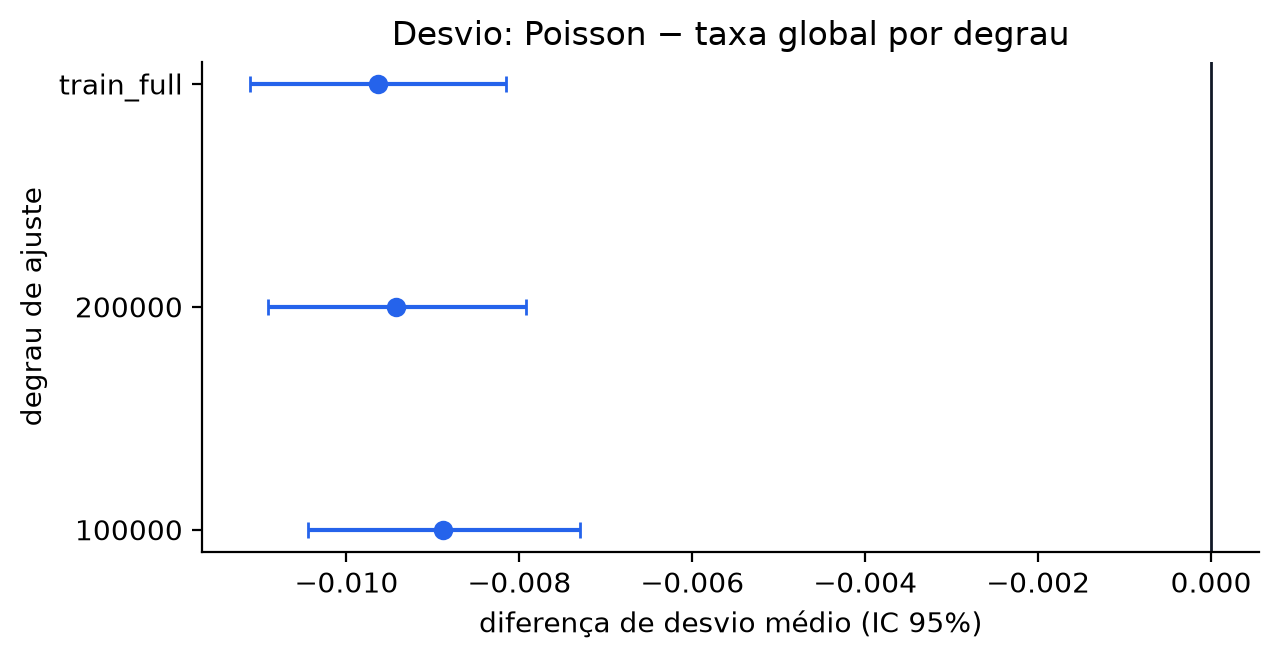

In [3]:
decision = s4["model_decision"]
display(artifacts.localize(decision, LANG))
plots.show(plots.plot_stability(decision, LANG))

### Insights

No treino inteiro (partição principal), o desvio médio é 0,32863 (taxa global), 0,31899 (Poisson) e 0,31910 (NB2). A diferença pareada Poisson − taxa global é -0,00964 (IC 95% -0,01111 a -0,00815; valores negativos favorecem o Poisson), e o erro absoluto da diferença de taxa global é 0,054 para o Poisson e 0,068 para a taxa global, de modo que as duas condições do parecer são cumpridas. O sinal do ganho de desvio é o mesmo nos três degraus (-0,00888 com 100 mil, -0,00942 com 200 mil e -0,00964 no treino inteiro). A condição de calibração global, porém, não se cumpre nos degraus menores: o erro do Poisson é 0,142 contra 0,131 (100 mil) e 0,020 contra 0,010 (200 mil). O NB2 melhora a log-verossimilhança frente ao Poisson em 0,00075 (IC 0,00036 a 0,00130), mas seu desvio médio é maior em 0,00011 (IC 0,00003 a 0,00019) e seu erro de taxa global é 0,258, maior que o do Poisson; as condições do NB2 não são cumpridas e o ganho de verossimilhança, isolado, é insuficiente para selecioná-lo. Na partição agrupada, que é uma sensibilidade com população própria, as condições do NB2 são cumpridas (diferença de desvio -0,00001, IC -0,00009 a 0,00007; erro de taxa global 0,055 contra 0,244); esse resultado mede a generalização a perfis distintos e não altera a decisão da partição principal.

## 3. Interpretação da exposição

**Pergunta.** Como se comparam, por faixa de exposição, a taxa observada e as previstas pelo Poisson com offset fixo e pelo diagnóstico com coeficiente livre de `log(Exposure)`? As taxas são `100 × Σμ / Σ Exposure` do grupo, calculadas das previsões diretas.

,faixa,registros,exposição,observed_rate_per_100,predicted_rate_poisson,diff_poisson,diff_poisson_lo,diff_poisson_hi,predicted_rate_poisson_free_exposure,diff_poisson_free_exposure,diff_poisson_free_exposure_lo,diff_poisson_free_exposure_hi,baixo suporte
0,"(0, 0.02]",2873,32.2187,238.9918,14.2353,-224.7565,-281.5361,-169.5894,134.5604,-104.4314,-160.9391,-50.0374,False
1,"(0.02, 0.08]",14314,916.7600,36.2145,12.4445,-23.7700,-28.3236,-19.4153,43.5083,7.2939,2.7534,11.6179,False
2,"(0.08, 0.25]",16322,"2,815.9400",23.6866,12.0673,-11.6193,-13.4583,-9.8619,23.3901,-0.2965,-2.1118,1.4410,False
3,"(0.25, 0.50]",19693,"7,714.6600",12.3661,11.4387,-0.9274,-1.7519,-0.1328,13.5760,1.2100,0.3847,2.0146,False
4,"(0.50, 0.75]",13882,"8,784.5000",9.9721,11.3045,1.3324,0.6494,1.9866,10.0449,0.0728,-0.6232,0.7261,False
5,"(0.75, 1)",9263,"8,079.5200",8.9981,10.6619,1.6639,0.9571,2.2909,8.0031,-0.9950,-1.6757,-0.3833,False
6,= 1,25042,"25,042.0000",6.9004,8.6950,1.7946,1.4735,2.1069,6.8727,-0.0277,-0.3479,0.2851,False
7,> 1,184,204.4500,3.4238,11.8880,8.4641,NaN,NaN,7.3221,3.8983,NaN,NaN,True
8,total,101573,"53,590.0487",10.0168,10.0711,0.0544,-0.2167,0.3044,10.1012,0.0844,-0.1837,0.3429,False


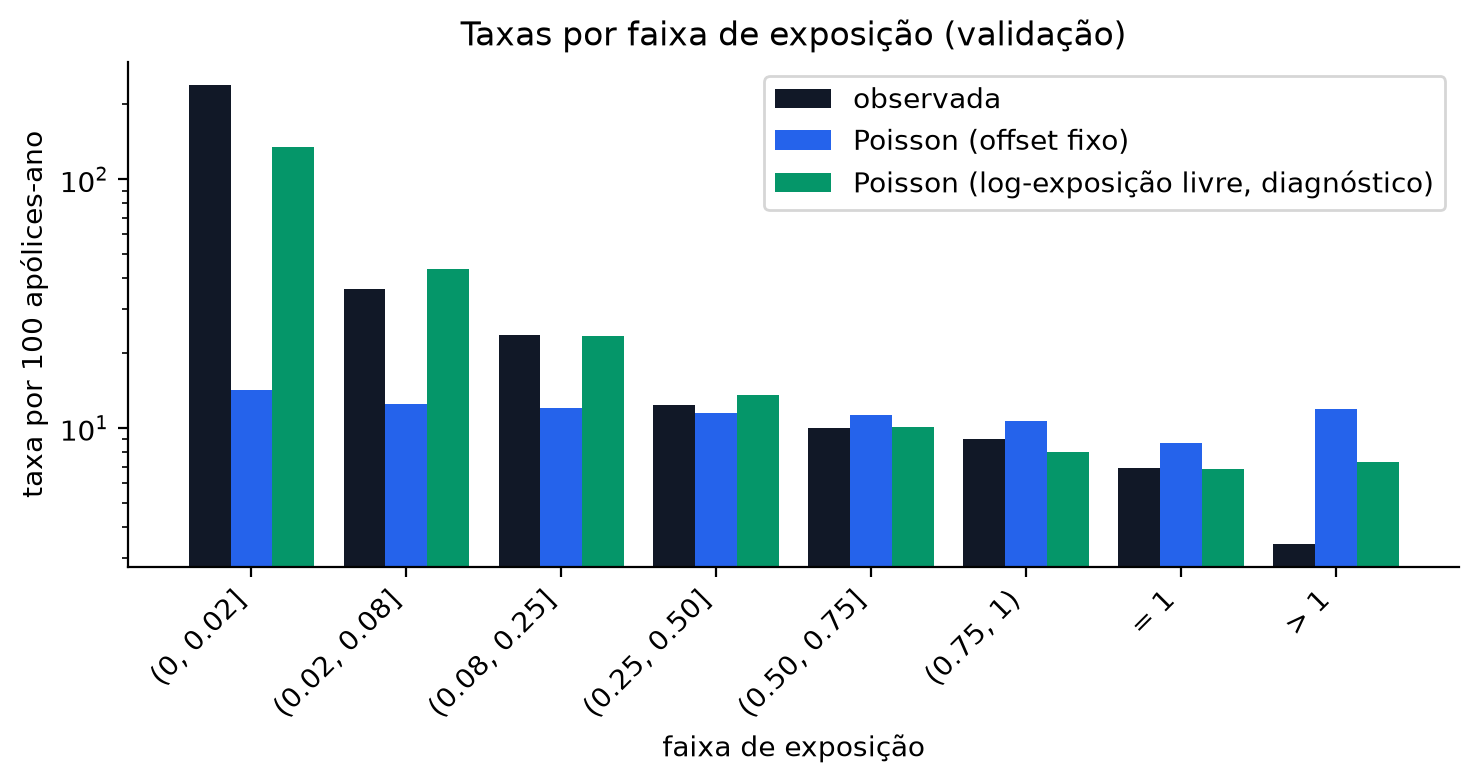

In [4]:
bands = s4["exposure_band_rates"]
cols = ["band", "rows", "exposure", "observed_rate_per_100",
        "predicted_rate_poisson", "diff_poisson", "diff_poisson_lo",
        "diff_poisson_hi", "predicted_rate_poisson_free_exposure",
        "diff_poisson_free_exposure", "diff_poisson_free_exposure_lo",
        "diff_poisson_free_exposure_hi", "low_support"]
display(artifacts.localize(bands[cols], LANG))
plots.show(plots.plot_exposure_rates(bands, LANG))

### Insights

Na faixa `(0; 0,02]`, a taxa observada é 238,99 por 100 apólices-ano, a prevista pelo Poisson com offset é 14,24 e a prevista pelo ajuste livre é 134,56: a melhora é parcial e o desvio permanece expressivo. Em exatamente um ano, o observado é 6,90, o offset prevê 8,70 e o ajuste livre, 6,87. O ajuste livre reduz os desvios na maioria das faixas (não em `(0,25; 0,50]`), mas o erro absoluto da diferença de taxa global sobe de 0,054 para 0,084. Os intervalos de 95% vêm do bootstrap pareado da etapa 3 e só existem onde há suporte. O ajuste livre é mantido como diagnóstico de associação com a duração observada no benchmark; a relação não sustenta extrapolação causal ou prospectiva da frequência para outra duração.

## 4. Diagnóstico formal de zeros

**Pergunta.** Quantos zeros são previstos, `Σ P(Y_i = 0)`, em comparação com os observados, no total e por faixa? Para os candidatos Poisson (incluindo a taxa global), `P(Y_i = 0) = exp(−μ_i)`; para o NB2, usa-se a expressão com a dispersão estimada.

,candidato,faixa,registros,exposição,zeros_observed,zeros_predicted,diff_pred_minus_obs,IC inf.,IC sup.,baixo suporte,zero_share_observed,zero_share_predicted
0,global,overall,101573,"53,590.0487",96496,"96,374.8778",-121.1222,-247.7327,4.6260,False,0.9500,0.9488
1,global,"(0, 0.02]",2873,32.2187,2801,"2,869.7533",68.7533,52.7164,86.7374,False,0.9749,0.9989
2,global,"(0.02, 0.08]",14314,916.7600,14000,"14,221.8731",221.8731,188.2801,256.6375,False,0.9781,0.9936
3,global,"(0.08, 0.25]",16322,"2,815.9400",15684,"16,040.6970",356.6970,305.6884,405.7248,False,0.9609,0.9828
4,global,"(0.25, 0.50]",19693,"7,714.6600",18789,"18,930.7832",141.7832,86.4001,198.9132,False,0.9541,0.9613
5,global,"(0.50, 0.75]",13882,"8,784.5000",13061,"13,024.2054",-36.7946,-88.0614,17.7014,False,0.9409,0.9382
6,global,"(0.75, 1)",9263,"8,079.5200",8588,"8,483.2291",-104.7709,-149.6058,-55.9864,False,0.9271,0.9158
7,global,= 1,25042,"25,042.0000",23396,"22,639.8166",-756.1834,-828.1577,-680.9087,False,0.9343,0.9041
8,global,> 1,184,204.4500,177,164.5201,-12.4799,NaN,NaN,True,0.9620,0.8941
9,poisson,overall,101573,"53,590.0487",96496,"96,406.5733",-89.4267,-210.5667,42.9631,False,0.9500,0.9491


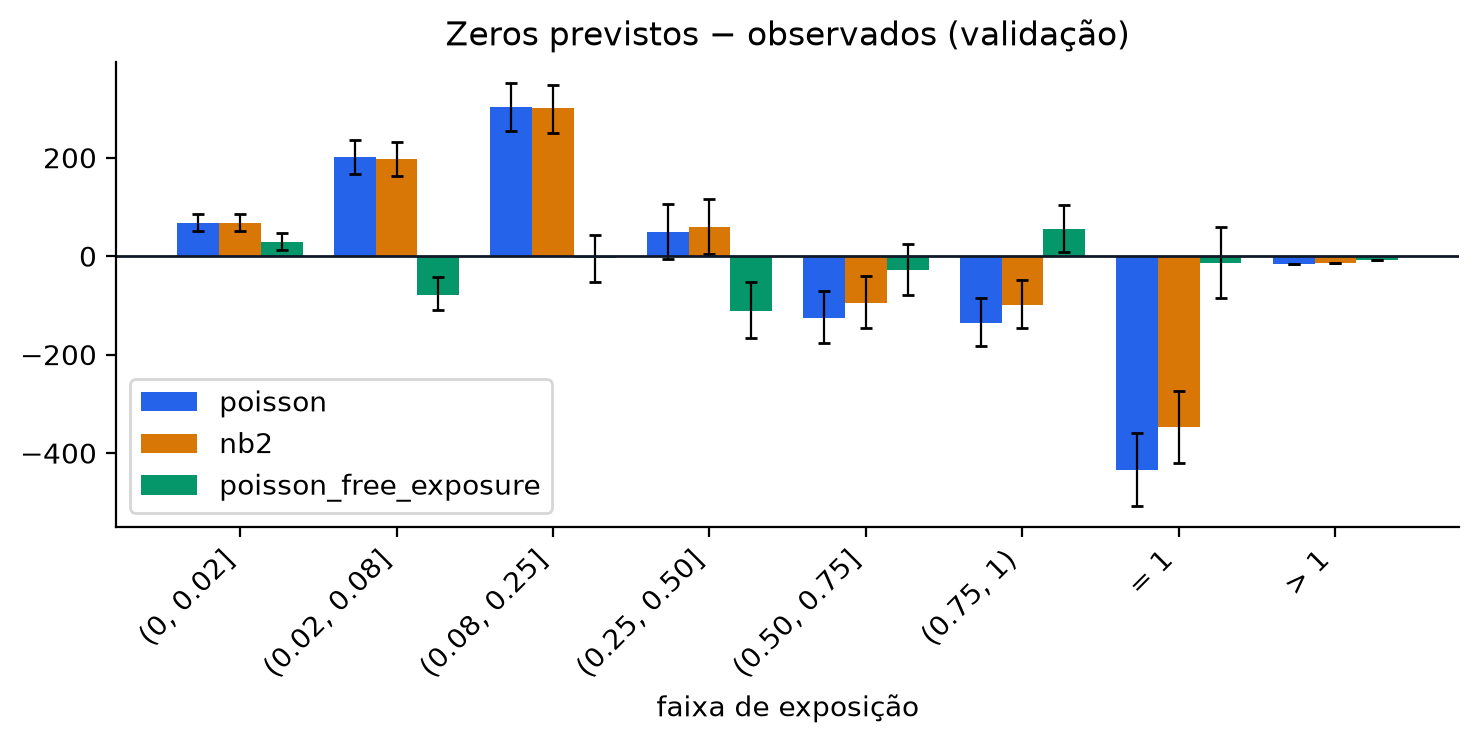

candidate
global                   True
nb2                      True
poisson                  True
poisson_free_exposure    True
Name: ok, dtype: bool

,bands_with_support_ci_below_zero,numeric_requirement_met,total_ci,total_ci_below_zero,total_diff
global,"(0.75, 1), = 1",False,"[-247.732699, 4.625978]",False,-121.1222
nb2,"(0.50, 0.75], (0.75, 1), = 1",False,"[-52.287517, 200.657534]",False,69.5231
poisson,"(0.50, 0.75], (0.75, 1), = 1",False,"[-210.566694, 42.963092]",False,-89.4267
poisson_free_exposure,"(0.02, 0.08], (0.25, 0.50]",True,"[-283.132737, -29.969319]",True,-160.2140


In [5]:
zeros = s4["zero_diagnostics"]
display(artifacts.localize(zeros, LANG))
plots.show(plots.plot_zero_diff(
    zeros, LANG, ("poisson", "nb2", "poisson_free_exposure")))
display(artifacts.zero_reconciliation_ok(s4))
display(artifacts.zero_gate_table(s4))

### Insights

As faixas reconciliam com o total para todos os candidatos (registros, exposição, zeros observados e previstos). No total, a diferença previstos − observados é -121,1 para a taxa global (IC -247,7 a 4,6), -89,4 para o Poisson com offset (IC -210,6 a 43,0) e 69,5 para o NB2 (IC -52,3 a 200,7); os três intervalos incluem zero, de modo que o critério numérico da etapa 2 não é cumprido no modelo de referência. O Poisson com offset superestima zeros nas faixas curtas e subestima nas longas (`(0.50, 0.75]`, `(0.75, 1)`, `= 1` têm intervalo abaixo de zero), isto é, o sinal depende da duração. O diagnóstico com coeficiente livre cumpre a parte numérica: -160,2 no total (IC -283,1 a -30,0), com déficits em `(0,02; 0,08]` (-78,0; IC -110,1 a -42,9) e em `(0,25; 0,50]` (-110,5; IC -166,3 a -51,9), ambas com suporte. Essa diferença entre os modelos é registrada separadamente: o critério se aplica ao modelo de referência, e o resultado do ajuste livre é um diagnóstico.

Um déficit indica que foram previstos menos zeros do que os observados. No total da validação, a alta proporção de apólices sem sinistro foi compatível com o Poisson de offset fixo. O déficit no diagnóstico com coeficiente livre mostra que essa comparação é sensível à forma de modelar a exposição. Como o déficit global do modelo de referência não se distinguiu de zero e o contrato de dados não sustentou a hipótese de um segundo processo que sempre gerasse zero, não foi necessário ajustar ZIP ou ZINB nesta avaliação.

## 5. Erros nas médias e diferenças de zeros

**Pergunta.** Os erros nas contagens por duração coexistem com as diferenças de zeros? A coluna reescalada ajusta `μ` por faixa para somar as contagens observadas e recalcula os zeros previstos; é apenas um diagnóstico e nunca é usada em taxas ou previsões.

In [6]:
display(artifacts.localize(s4["mean_vs_zero_by_band"], LANG))

,candidato,faixa,registros,claims_observed,claims_predicted,claims_diff_pred_minus_obs,zeros_observed,zeros_predicted,zeros_diff_pred_minus_obs,zeros_diff_if_band_rescaled
0,poisson,"(0, 0.02]",2873,77,4.5864,-72.4136,2801,"2,868.4209",67.4209,-2.9978
1,poisson,"(0.02, 0.08]",14314,332,114.0865,-217.9135,14000,"14,200.5921",200.5921,-12.3171
2,poisson,"(0.08, 0.25]",16322,667,339.8079,-327.1921,15684,"15,987.3923",303.3923,-9.2632
3,poisson,"(0.25, 0.50]",19693,954,882.4567,-71.5433,18789,"18,838.1559",49.1559,-17.8127
4,poisson,"(0.50, 0.75]",13882,876,993.0425,117.0425,13061,"12,935.8254",-125.1746,-18.3244
5,poisson,"(0.75, 1)",9263,727,861.4330,134.4330,8588,"8,451.9926",-136.0074,-15.7597
6,poisson,= 1,25042,1728,"2,177.4134",449.4134,23396,"22,962.2838",-433.7162,-20.0520
7,poisson,> 1,184,7,24.3049,17.3049,177,161.9102,-15.0898,0.1960
8,poisson_free_exposure,"(0, 0.02]",2873,77,43.3536,-33.6464,2801,"2,830.0834",29.0834,-3.6310
9,poisson_free_exposure,"(0.02, 0.08]",14314,332,398.8671,66.8671,14000,"13,921.9991",-78.0009,-13.2312


### Insights

No Poisson com offset, os erros de contagem por faixa têm sinal oposto ao das diferenças de zeros: onde as contagens são subestimadas, os zeros são superestimados, e vice-versa. Quando `μ` é reescalado por faixa para igualar as contagens observadas, as diferenças de zeros por faixa se reduzem a poucas dezenas, com saldo de -96,3 no Poisson e -115,1 no diagnóstico livre. Esse saldo residual é pequeno e não tem intervalo associado; ele não permite concluir por um segundo processo gerador de zeros.

## 6. O que o contrato de dados sustenta sobre um segundo processo

**Pergunta.** O dicionário e o esquema sustentam uma hipótese plausível para um segundo processo gerador de zeros, requisito separado do critério numérico?

In [7]:
display(artifacts.second_process_table(s4))

criterion                ZIP/ZINB na etapa 4 somente se o modelo de con...
hypothesis_documented                                                False
contract_evidence        O dicionario define ClaimNb como numero de sin...
decision                 encerrar com os modelos de contagem ja avaliad...
dtype: object

### Insights

O dicionário define `ClaimNb` como número de sinistros no período de exposição e `Exposure` como duração em anos (Dutang & Charpentier, 2018); não descreve apólices sem risco, não há datas nem identificador de unidade superior, e o instante de medição de `BonusMalus` é desconhecido. Assim, nenhuma hipótese de segundo processo é sustentada pelo contrato. O teste de Vuong não é usado como regra de seleção, pois seu emprego para testar inflação de zeros é questionado na literatura (Wilson, 2015). Como o modelo de referência não cumpre o critério numérico e não há hipótese documentada, a decisão desta rodada é encerrar com os modelos de contagem já avaliados, sem ajustar ZIP ou ZINB.

## 7. Modelo congelado e verificação

**Pergunta.** O que foi congelado, e a verificação restaura o artefato e reproduz a validação aprovada sem reajustar nem reaprender o pré-processamento?

In [8]:
frozen = s4["frozen_model"]
display(pd.Series({
    "model": frozen["model"], "reference": frozen["reference"],
    "columns": len(frozen["estimator"]["columns"]),
    "n_fit": frozen["estimator"]["n_fit"],
    "global_rate": frozen["global_rate"]["rate"],
    "bonus_malus_included": frozen["estimator"]["bonus_malus_included"],
    "training_sample_sha256": frozen["training_sample"]["ids_sha256"]}))
display(pd.Series(frozen["hashes"]))
display(pd.Series({k: v for k, v in s4["verify_freeze"].items()
                   if not isinstance(v, dict)}))
display(pd.Series(s4["verify_freeze"]["frozen_reference"]))

model                                                  poisson_offset_fixed
reference                                                       global_rate
columns                                                                  68
n_fit                                                                474581
global_rate                                                          0.1008
bonus_malus_included                                                  False
training_sample_sha256    2a1dc6791f5f6417818ef6533ad04f14af4daa417c7822...
dtype: object

arff_sha256                         a45363e056e2ea56408b38eeb9d4d04d7f6c6982eb7a14...
assignments_sha256                  f14f53509d63ff468f025fd43096a5c2d12ba3fdd48529...
partition_config_sha256             3bc52dca60401a3eedbccfc3b689216dc02ddfba0d7a79...
protocol_config_sha256              e43e69566690ba98411620e8315bbc27aa00f6702e9cba...
stage3_coefficients_sha256          2c080c077a690c440ede9951aa43a6efb9946bac963448...
stage3_comparison_config_sha256     c0c5001514f67b4cebfe5649cd60392ee2e272db173ec4...
stage3_intervals_sha256             d31e9e8eb360038263d40d88b8d81e631c70c2f19c5d2c...
stage3_preprocessing_sha256         86fddf12dc071564df6a758dbcc2264378a1025794ffbd...
stage3_protocol_amendment_sha256    b4274c81e4d32e5351e7502dadeeb022665dbc3a93cdd3...
stage3_validation_metrics_sha256    cea8459863517021cfefd50546f2660d0fc3473ae08290...
dtype: str

approved_stage3_ok         True
code_modules_unchanged     True
ok                         True
preprocessor_relearned    False
refit_performed           False
test_used                 False
dtype: bool

max_abs_diff   0.0000
max_rel_diff   0.0000
n_compared         77
ok               True
dtype: object

### Insights

O artefato congela o Poisson com offset fixo, ajustado em 474.581 registros do treino com 68 colunas e sem `BonusMalus`, e a taxa global de 10,084 por 100 apólices-ano calculada no mesmo treino, com o pré-processador já ajustado, a ordem das colunas, os coeficientes e os hashes de origem. A verificação restaurou o estado persistido, sem reajustar o estimador nem reaprender o pré-processamento, e reproduziu 77 agregados de validação com diferença absoluta máxima de 0,000000000000, dentro da tolerância declarada (`rtol = 1e-9`, `atol = 1e-12`); os coeficientes são persistidos com 17 dígitos significativos e restaurados sem perda. O desvio por duração (seção 3) é uma limitação do Poisson selecionado: o offset fixo subestima as exposições muito curtas e superestima as longas.

## 8. Roteiro da etapa 5 e limitações

**Pergunta.** Como a avaliação final será aplicada, e o que deve ser declarado como limitação?

In [9]:
script = s4["stage5_script"]
display(pd.Series({k: v for k, v in script.items()
                   if k in ("model", "reference", "primary_metric",
                            "paired_comparison", "calibration",
                            "test_access", "outputs")}))
display(pd.Series(script["limitations_to_state"], name="limitation"))

calibration          totais previstos e observados e diferenca prev...
model                                             poisson_offset_fixed
outputs                                               outputs/etapa_05
paired_comparison    diferenca de desvio Poisson - taxa global, IC ...
primary_metric       desvio medio de Poisson por registro, previsoe...
reference                                                  global_rate
test_access          uma unica execucao sobre a particao de teste, ...
dtype: str

0    o offset fixo subestima as exposicoes muito cu...
1                     resultados internos ao benchmark
2                            BonusMalus fora do modelo
3                                         sem ZIP/ZINB
Name: limitation, dtype: str

### Insights

A etapa 5 aplicará o roteiro uma única vez à partição de teste, após o aceite, com o Poisson congelado e a taxa global de referência, o desvio médio de Poisson, a diferença pareada contra a taxa global, a calibração das previsões diretas por segmento com a faixa mais curta visível, as reconciliações e a verificação dos hashes. As limitações a declarar são o desvio por duração do offset fixo, a restrição ao benchmark, a exclusão de `BonusMalus` e a ausência de ZIP e ZINB. Os resultados são internos ao benchmark e `production_eligible` permanece falso.

## Referências

- Dutang, C., & Charpentier, A. (2018). *CASdatasets: Insurance datasets* (freMTPL2freq). https://dutangc.github.io/CASdatasets/reference/freMTPL.html
- Wilson, P. (2015). The misuse of the Vuong test for non-nested models to test for zero-inflation. *Economics Letters, 127*, 51–53. https://doi.org/10.1016/j.econlet.2014.12.029